# Machine Learning ki Teesri Class: Logistic Regression 🩺

**AI for Everyone** | Instructor: Mian Muhammad Azam Ayaz

Ab tak humne **Regression** kiya, yani **number** predict kiya (ghar ki price, salary). Aaj hum **Classification** seekhenge, yani **category** predict karna. Hamara sawal hoga:

> Is mareez ko **diabetes hai ya nahi?** (Haan = 1, Nahi = 0)

Aaj kya seekhenge:
1. **Classification** kya hai aur Regression se kaise alag hai
2. **Logistic Regression** aur **Sigmoid function**
3. Data mein **chhupi hui missing values** (zero wali) pakarna aur theek karna
4. **Class imbalance** aur `stratify`
5. **Confusion Matrix, Precision, Recall, F1** (accuracy kaafi kyun nahi hoti)
6. **Threshold** badal kar model ka rawaiya badalna
7. **C** aur **max_iter** hyperparameters
8. Model ko **Pickle** mein save aur load karna

Dataset: `diabetes.csv` (768 khawateen ka medical data)

> ⚠️ Ye notebook sirf **seekhne** ke liay hai. Asal mein diabetes ki tashkhees sirf doctor aur lab test se hoti hai.

> **Kaise chalana hai:** Har cell ko upar se neeche order mein run karo. `Shift + Enter`

---
## Part 1: Classification kya hai? 🗂️

Supervised Learning ki 2 types yaad karo (pehli class se):

| | Regression | Classification |
|---|---|---|
| Output | **Number** | **Category / Class** |
| Sawal | "Kitna?" | "Kaunsa?" ya "Haan ya Nahi?" |
| Misaal | Ghar ki price, salary | Email spam hai ya nahi, mareez ko diabetes hai ya nahi |
| Pichli classes | Linear, Polynomial ✅ | **Aaj: Logistic Regression** |

Jab sirf **2 jawab** hon (Haan/Nahi, 1/0) to isko **Binary Classification** kehte hain.

---
## Part 2: Logistic Regression kya hai? 📉➡️📈

**Definition:** Logistic Regression ek Supervised Learning algorithm hai jo **classification** ke liay use hota hai. Ye batata hai ke kisi cheez ke kisi class mein hone ka **probability (chance)** kitna hai, 0 se 1 ke beech. Phir ek **threshold** (aam tor pe 0.5) se faisla karta hai.

### Naam mein "Regression" kyun hai? 🤔
Kyunke andar se ye bilkul Linear Regression ki tarah shuru hota hai:

$$ z = m_1x_1 + m_2x_2 + ... + c $$

Lekin masla ye hai ke $z$ koi bhi number ho sakta hai: -50, 3, 200. Probability to sirf **0 se 1** ke beech honi chahiye! Isliay aakhir mein ek jaadu ka function lagta hai: **Sigmoid**.

### Sigmoid Function ✨

$$ \sigma(z) = \frac{1}{1 + e^{-z}} $$

Ye kisi bhi number ko **0 aur 1 ke beech** daba deta hai:
- Bohat bara positive number ➜ 1 ke qareeb (pakka diabetes)
- Bohat bara negative number ➜ 0 ke qareeb (pakka nahi)
- Zero ➜ bilkul 0.5 (pata nahi, 50/50)

Chalo isko graph pe dekhte hain 👇

## Step 1: Libraries import karna 📦

Nayi cheezein:
- **LogisticRegression:** Aaj ka main model
- **SimpleImputer:** Missing values ko khud fill karta hai
- **confusion_matrix, classification_report** waghaira: Classification model ko check karne ke tools

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, log_loss)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Sab libraries load ho gayin ✅")

Sab libraries load ho gayin ✅


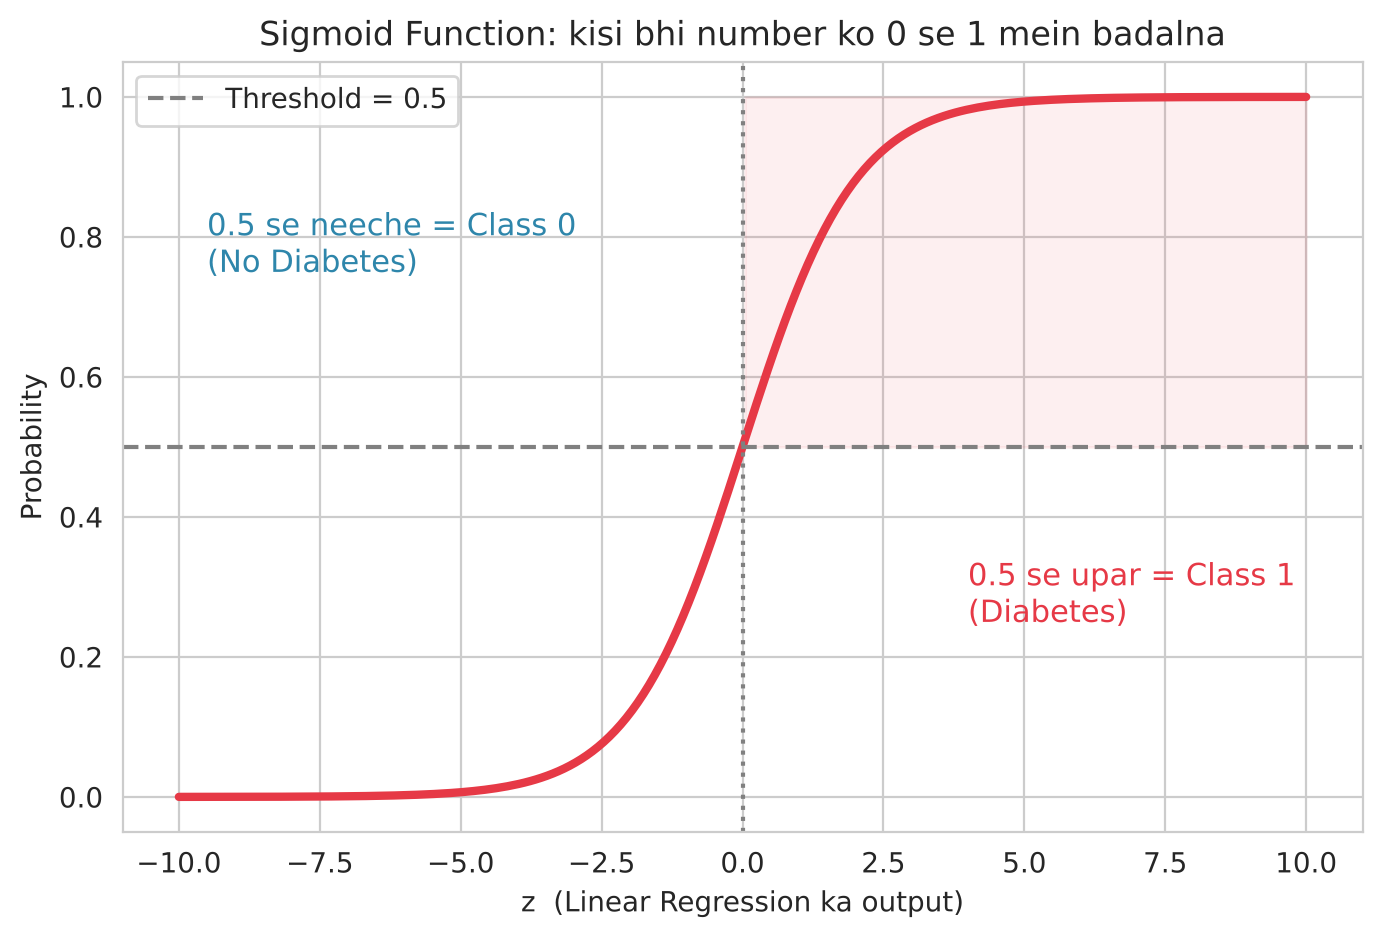

In [2]:
z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid, color="#E63946", linewidth=3)
plt.axhline(0.5, color="gray", linestyle="--", label="Threshold = 0.5")
plt.axvline(0, color="gray", linestyle=":")
plt.fill_between(z, 0.5, 1, where=sigmoid >= 0.5, color="#E63946", alpha=0.08)
plt.text(4, 0.25, "0.5 se upar = Class 1\n(Diabetes)", fontsize=11, color="#E63946")
plt.text(-9.5, 0.75, "0.5 se neeche = Class 0\n(No Diabetes)", fontsize=11, color="#2E86AB")
plt.xlabel("z  (Linear Regression ka output)")
plt.ylabel("Probability")
plt.title("Sigmoid Function: kisi bhi number ko 0 se 1 mein badalna")
plt.legend()
plt.show()

Dekho, ye **S-shape** ka curve hai. Model ka output kuch bhi ho, sigmoid usay 0 aur 1 ke beech le aata hai.

**Misaal:** Model ne kisi mareez ke liay probability **0.82** nikali. 0.82 > 0.5, to faisla: **Diabetes hai (1)**. Agar 0.30 aati to faisla: **Nahi hai (0)**.

---
## Step 2: Dataset load karna 📂

> **Google Colab use kar rahe ho?** Upload wali lines ke aage se `#` hata do, run karo, aur `diabetes.csv` select kar lo.

In [3]:
# Sirf Google Colab ke liay (zaroorat ho to # hata do):
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Columns ka matlab:
- `Pregnancies`: Kitni baar pregnancy hui
- `Glucose`: Khoon mein sugar ka level
- `BloodPressure`: Blood pressure (mm Hg)
- `SkinThickness`: Bazu ki skin ki motai (mm)
- `Insulin`: Khoon mein insulin ka level
- `BMI`: Body Mass Index (wazan aur qad ka hisaab)
- `DiabetesPedigreeFunction`: Khandan mein diabetes ki history ka score
- `Age`: Umar
- `Outcome`: **0 = Diabetes nahi, 1 = Diabetes hai** (ye hamara **target y** hai)

---
## Step 3: Data ko samajhna 🔍

In [4]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print()
print("Missing values (NaN):")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Rows: 768 | Columns: 9

Missing values (NaN):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


Wah, na koi missing value, na duplicate! Data bilkul saaf lagta hai... **lekin ruko!** 🕵️ `describe()` dekhte hain:

In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


---
# 🧹 Step 4: Data Preprocessing

### 4.1 Chhupi hui missing values (Hidden Missing Values) 🕵️

`min` wali row ghaur se dekho. **Glucose = 0, BloodPressure = 0, BMI = 0?** 😳

Kisi zinda insaan ka blood pressure ya BMI **zero ho hi nahi sakta!** Asal mein jis ne data banaya, usne khali jagah pe **0 likh diya**. Ye **chhupi hui missing values** hain. `isnull()` inhe nahi pakar sakta kyunke technically wahan ek number (0) likha hai.

> 💡 **Lesson:** Sirf `isnull()` pe bharosa na karo. Hamesha socho ke har column mein konsi values **asal zindagi mein mumkin** hain.

Chalo ginte hain kitne zeros hain:

In [6]:
zero_not_possible = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zeros = (df[zero_not_possible] == 0).sum()
pd.DataFrame({"Zero values": zeros, "Percentage": (zeros / len(df) * 100).round(1)})

,Zero values,Percentage
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


`Insulin` mein to **lagbhag aadhi** values zero hain, aur `SkinThickness` mein ek tihai!

> ℹ️ `Pregnancies` mein 0 bilkul theek hai (kabhi pregnancy na hui ho), isliay usay nahi chherna.

**Hal:** Pehle in zeros ko asal **missing (NaN)** bana dete hain, taa ke computer ko pata chale ye khali hain.

In [7]:
df[zero_not_possible] = df[zero_not_possible].replace(0, np.nan)

df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Ab asal tasveer saamne aa gayi! 👀

### 4.2 Missing values ko fill kaise karein? (Median)

Itni zyada rows drop karein to aadha data hi chala jaye ga. Isliay **fill** karein ge.

**Mean (average) ya Median?** Medical data mein kuch log bohat extreme hote hain (jaise Insulin 846). Ye **mean** ko apni taraf kheench lete hain. **Median** (beech wali value) pe extreme values ka asar nahi hota. Isliay hum **median** use karein ge.

**Misaal:** 5 logon ki salary: 20k, 25k, 30k, 35k, 10 lakh. Mean = 2.2 lakh (kisi ki bhi salary itni nahi!) Median = 30k (zyada sahi tasveer).

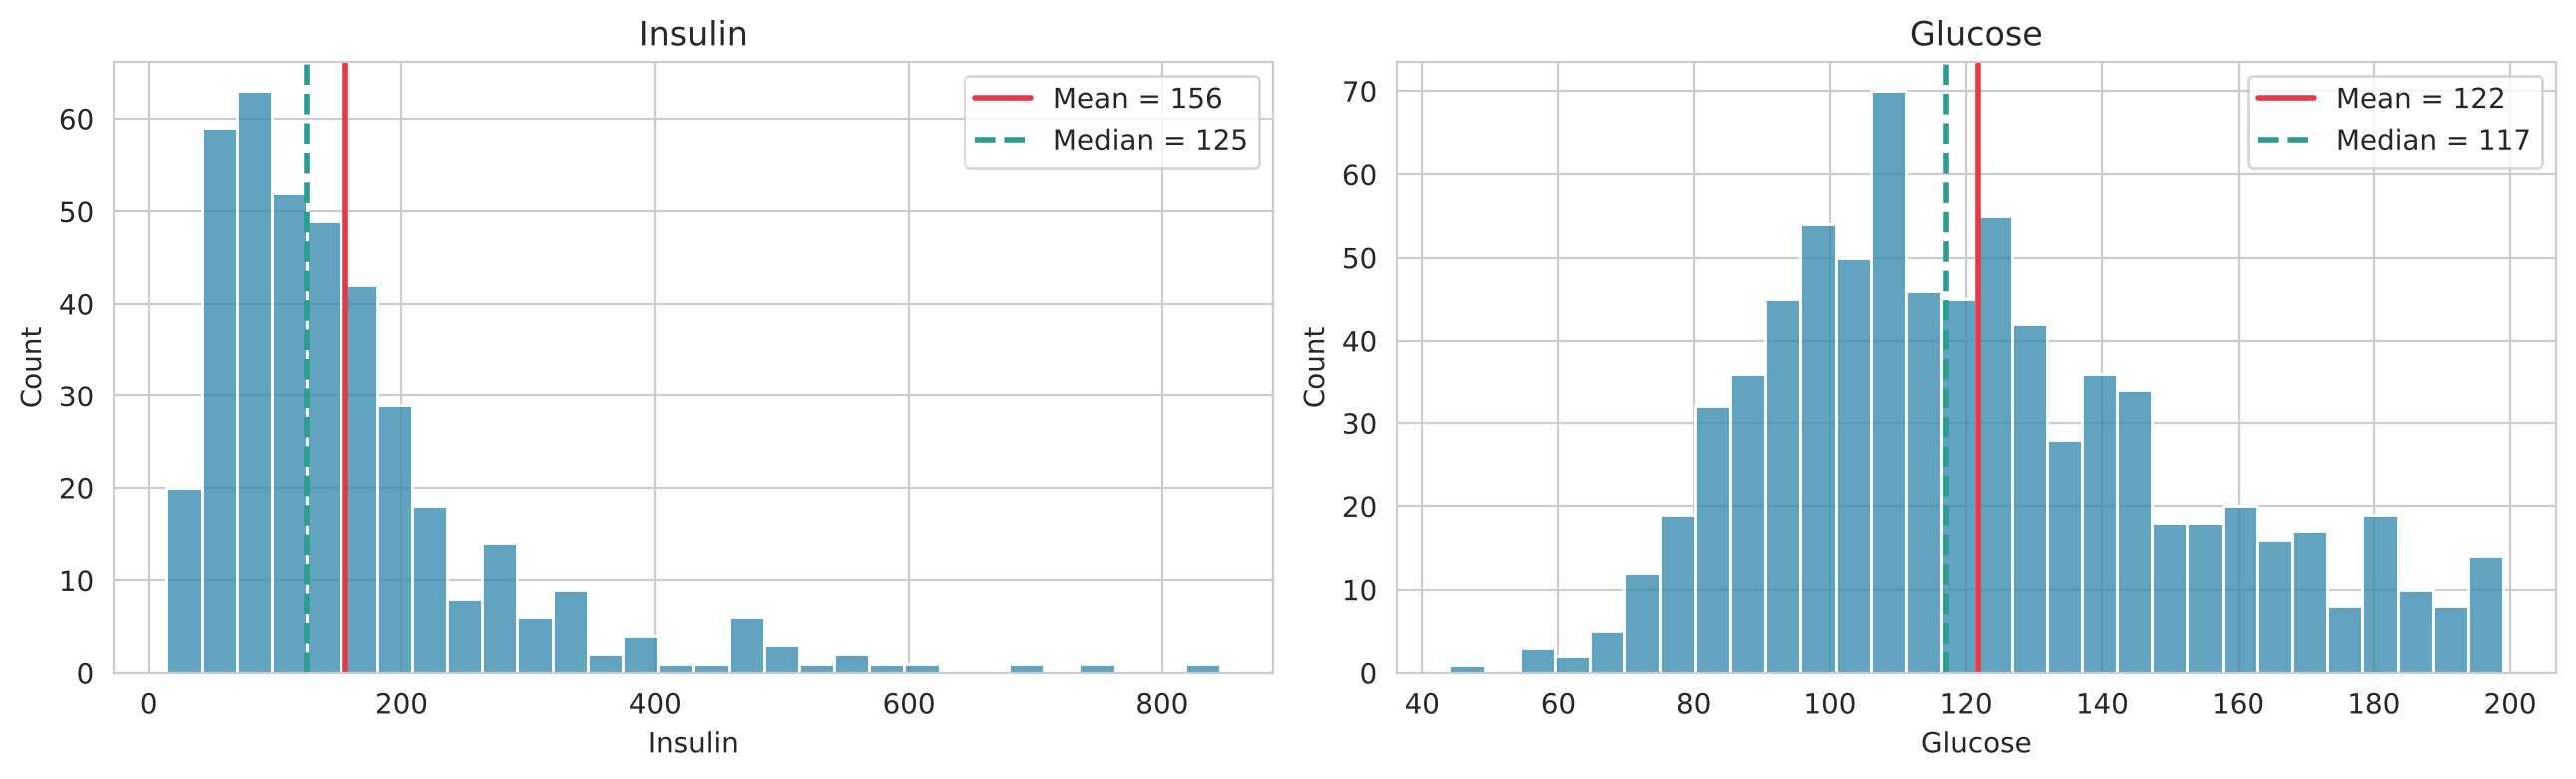

In [8]:
cols = ["Insulin", "Glucose"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, cols):
    sns.histplot(df[col], bins=30, ax=ax, color="#2E86AB")
    ax.axvline(df[col].mean(), color="#E63946", linewidth=2, label=f"Mean = {df[col].mean():.0f}")
    ax.axvline(df[col].median(), color="#2A9D8F", linewidth=2, linestyle="--", label=f"Median = {df[col].median():.0f}")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

Insulin ka graph daaein taraf lamba khinch raha hai (kuch logon ki bohat zyada values), isliay mean aur median mein farq hai.

### ⚠️ Ek bohat zaroori baat: Data Leakage
Median hum **poore data** se nahi nikalein ge, warna test data ki maloomat chupke se training mein aa jaye gi (jaise exam se pehle paper leak ho jaye 📝). Median sirf **training data** se nikale ga aur phir wohi test pe lagay ga.

Ye kaam **Pipeline** ke andar `SimpleImputer` khud sahi tareeqe se kar dega. Hum isay Step 6 mein lagayein ge.

### 4.3 Class Imbalance ⚖️
Dekhte hain kitne logon ko diabetes hai aur kitno ko nahi:

Outcome
0    500
1    268
Name: count, dtype: int64

No Diabetes: 65%   |   Diabetes: 35%


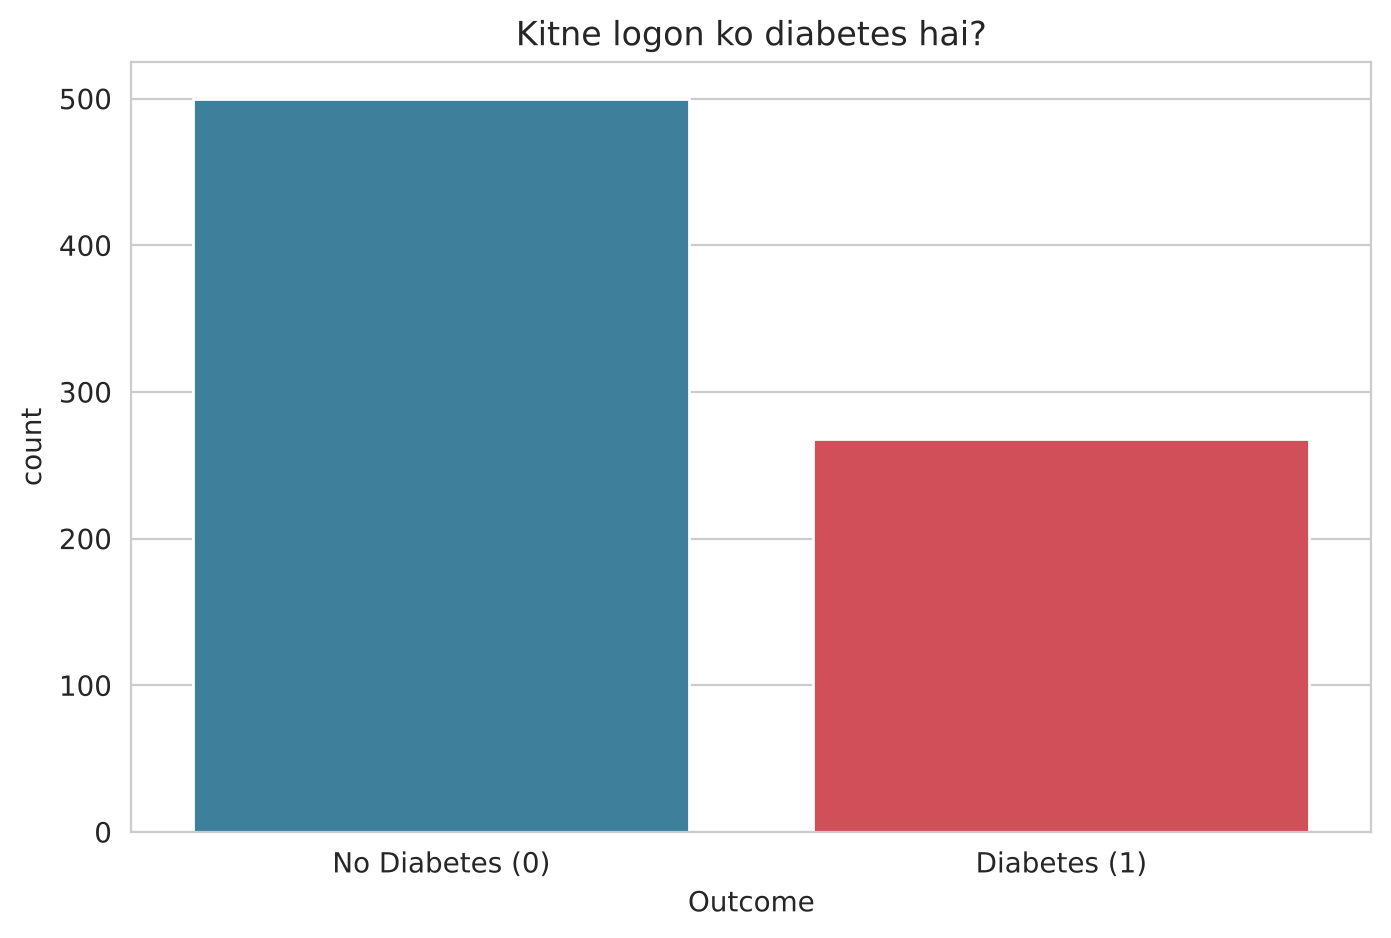

In [9]:
counts = df["Outcome"].value_counts()
print(counts)
print()
print(f"No Diabetes: {counts[0] / len(df):.0%}   |   Diabetes: {counts[1] / len(df):.0%}")

sns.countplot(x="Outcome", data=df, hue="Outcome", palette=["#2E86AB", "#E63946"], legend=False)
plt.xticks([0, 1], ["No Diabetes (0)", "Diabetes (1)"])
plt.title("Kitne logon ko diabetes hai?")
plt.show()

**65% vs 35%.** Dono classes barabar nahi hain. Isko **Class Imbalance** kehte hain.

Iske 2 asar hain:
1. Train/Test split karte waqt `stratify=y` lagayein ge, taa ke **dono hisson mein yahi 65/35 ratio** rahe. Warna ho sakta hai test mein diabetes wale bohat kam aa jayein.
2. **Accuracy dhoka de sakti hai!** Ek bewaqoof model jo har kisi ko "No Diabetes" keh de, wo bhi **65% accurate** hoga, lekin ek bhi mareez nahi pakray ga. 😬 Isliay hum Precision aur Recall bhi dekhein ge.

### 4.4 Features ka Diabetes se relation

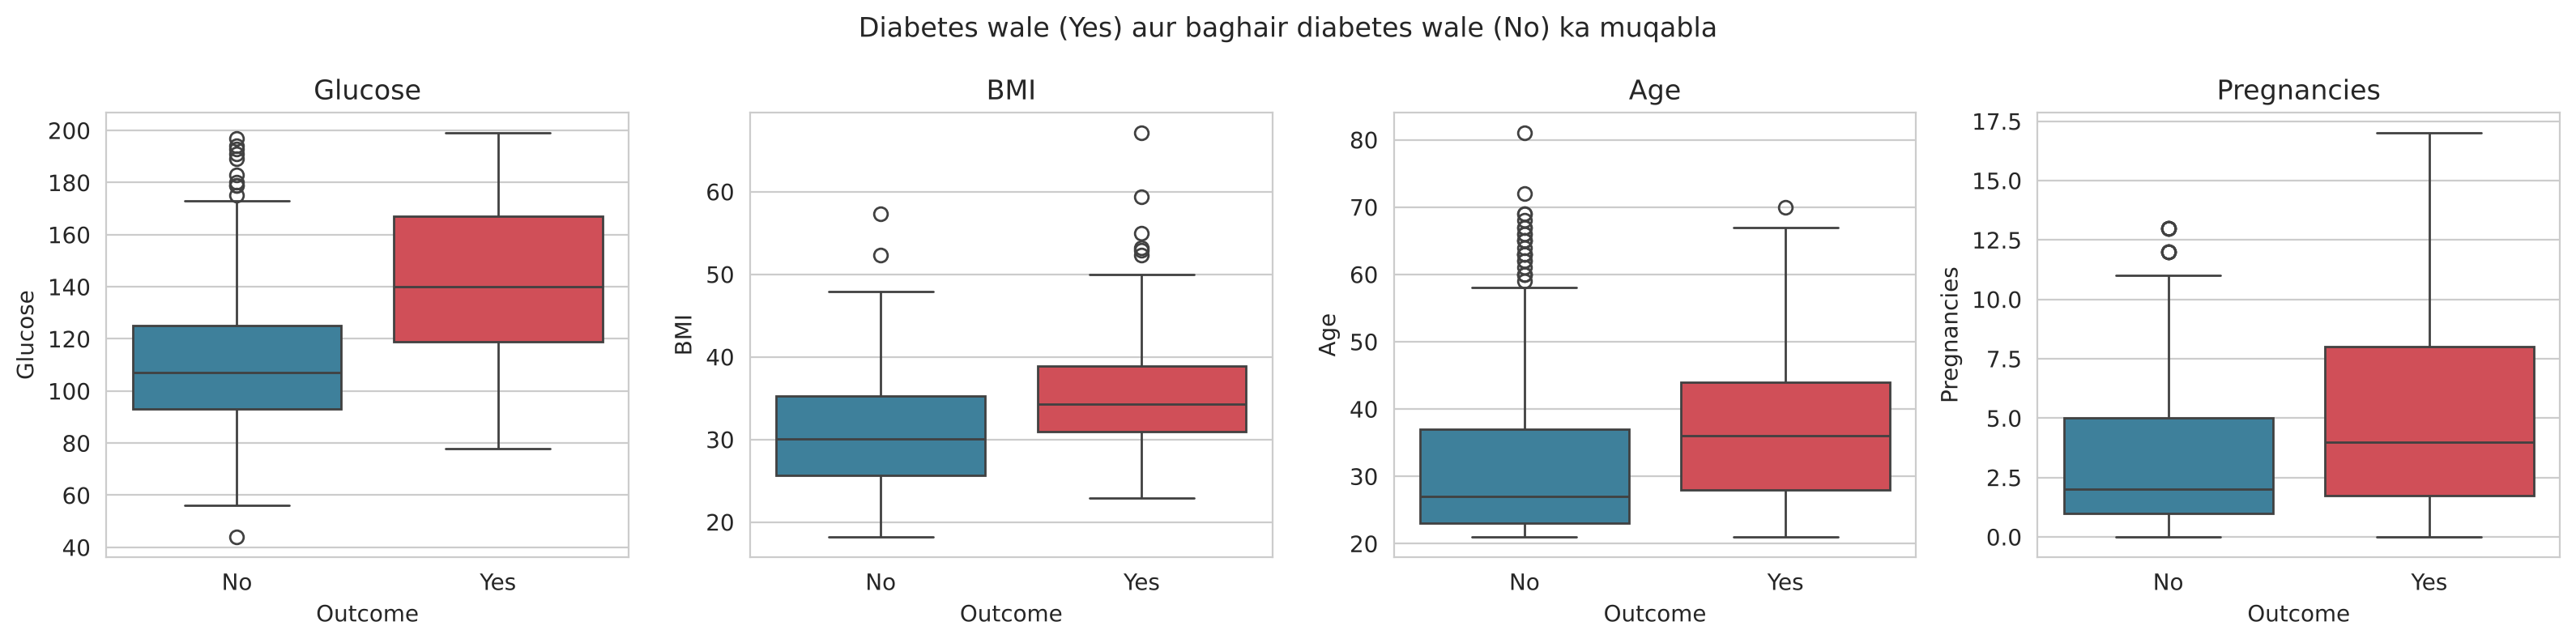

In [10]:
features = ["Glucose", "BMI", "Age", "Pregnancies"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, features):
    sns.boxplot(x="Outcome", y=col, data=df, ax=ax, hue="Outcome",
                palette=["#2E86AB", "#E63946"], legend=False)
    ax.set_xticks([0, 1], ["No", "Yes"])
    ax.set_title(col)
plt.suptitle("Diabetes wale (Yes) aur baghair diabetes wale (No) ka muqabla")
plt.tight_layout()
plt.show()

**Observation:** Diabetes walon ka **Glucose saaf taur pe zyada** hai. BMI aur Age bhi thore zyada hain. Matlab Glucose sab se important feature ho sakta hai.

---
## Step 5: X aur y, aur Train/Test split ✂️

In [11]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y   # stratify = ratio barabar rakho
)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print(f"Train mein diabetes: {y_train.mean():.0%}   |   Test mein diabetes: {y_test.mean():.0%}")

Training rows: 614 | Testing rows: 154
Train mein diabetes: 35%   |   Test mein diabetes: 35%


`stratify` ki wajah se dono mein **35%** diabetes wale hain. ✅

---
## Step 6: Pipeline banana 🔗

Hamare 3 steps:
1. **SimpleImputer(strategy="median"):** Missing values ko training data ki median se fill karo
2. **StandardScaler:** Sab features ko ek jaisi range mein lao (Insulin 800 tak jata hai, DiabetesPedigree sirf 2 tak). Logistic Regression scaled data pe behtar aur jaldi seekhta hai
3. **LogisticRegression:** Model

### Do important hyperparameters 🎛️

**1) `C` (Regularization ki taaqat)**
- Regularization model ko **ratta maarne (overfitting) se rokti** hai
- **C chhota** (jaise 0.01) ➜ zyada rok tok ➜ simple model
- **C bara** (jaise 100) ➜ kam rok tok ➜ model data ke bohat qareeb fit hota hai
- Socho C ek **strict teacher** ka ulta hai: C jitna kam, teacher utna strict 👨‍🏫

**2) `max_iter` (Maximum iterations)**
- Pichli class mein epochs parhe the na? Logistic Regression bhi **qadam ba qadam** seekhta hai (iske paas Linear Regression jaisa seedha formula nahi hota)
- `max_iter` batata hai model **zyada se zyada kitne qadam** le sakta hai sahi jawab tak pohanchne ke liay
- Agar kam ho aur model pohanch na paye to sklearn `ConvergenceWarning` deta hai. Tab `max_iter` barha do

In [12]:
def make_model(C=1.0, max_iter=1000):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("model",   LogisticRegression(C=C, max_iter=max_iter))
    ])

print("Model banane wala function tayyar ✅")

Model banane wala function tayyar ✅


### max_iter ka asar dekhte hain 👀
Har baar thore zyada qadam de kar model train karte hain aur dekhte hain ghalti (**Log Loss**) kaise kam hoti hai. Log Loss classification ka "loss" hai: model ghalat jawab pe jitna **pur-yaqeen** ho, utni zyada saza.

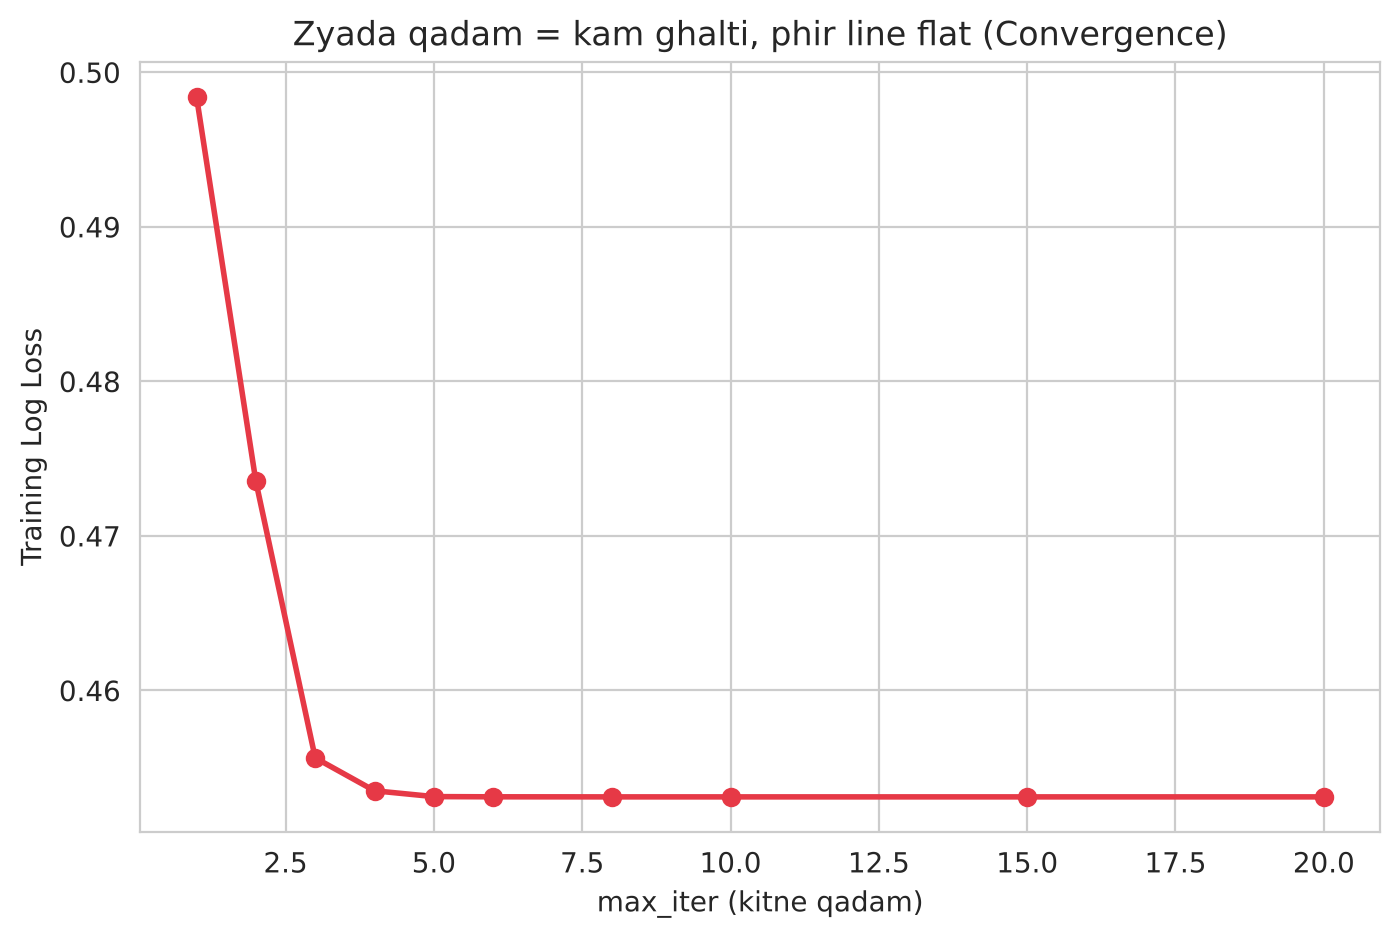

In [13]:
import warnings
from sklearn.exceptions import ConvergenceWarning

steps = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
losses = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)   # demo ke liay warning chhupa di
    for it in steps:
        m = make_model(max_iter=it).fit(X_train, y_train)
        losses.append(log_loss(y_train, m.predict_proba(X_train)))

plt.plot(steps, losses, "o-", color="#E63946", linewidth=2)
plt.xlabel("max_iter (kitne qadam)")
plt.ylabel("Training Log Loss")
plt.title("Zyada qadam = kam ghalti, phir line flat (Convergence)")
plt.show()

Pehle chand qadamon mein ghalti tezi se girti hai, phir **flat** ho jati hai. Yahi **convergence** hai. Is chhote data pe model bohat jaldi pohanch jata hai, isliay `max_iter=1000` hamare liay kaafi se zyada hai.

---
## Step 7: Behtareen C dhoondna (Cross Validation) 🔄
Pichli class ki tarah, test data ko chhuay baghair, training data pe 5-fold Cross Validation se best C chunein ge.

In [14]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
cv_scores = []

for C in C_values:
    score = cross_val_score(make_model(C=C), X_train, y_train, cv=5, scoring="accuracy").mean()
    cv_scores.append(score)
    print(f"C = {C:<6}  ->  Cross Validation Accuracy = {score:.3f}")

best_C = C_values[int(np.argmax(cv_scores))]
print("\nBest C:", best_C)

C = 0.001   ->  Cross Validation Accuracy = 0.651


C = 0.01    ->  Cross Validation Accuracy = 0.770
C = 0.1     ->  Cross Validation Accuracy = 0.779
C = 1       ->  Cross Validation Accuracy = 0.782
C = 10      ->  Cross Validation Accuracy = 0.782
C = 100     ->  Cross Validation Accuracy = 0.782

Best C: 1


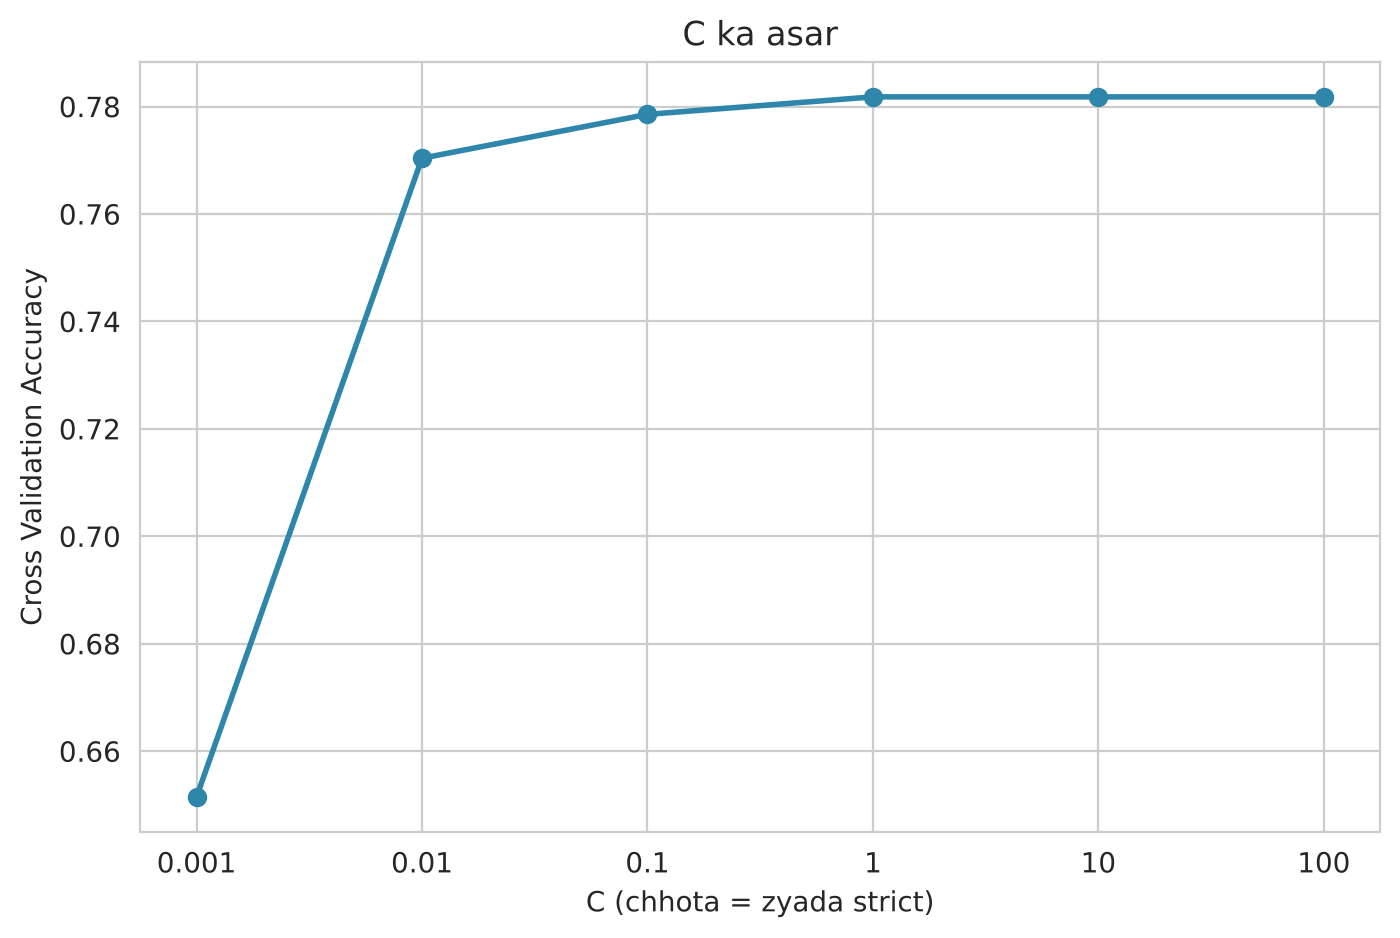

In [15]:
plt.plot([str(c) for c in C_values], cv_scores, "o-", color="#2E86AB", linewidth=2)
plt.xlabel("C (chhota = zyada strict)")
plt.ylabel("Cross Validation Accuracy")
plt.title("C ka asar")
plt.show()

**C bohat chhota (0.001)** pe model itna strict ho gaya ke kuch seekh hi nahi paaya (**underfitting**). Thora sa C barhte hi accuracy upar aa gayi aur phir lagbhag same rahi.

---
## Step 8: Final model train karna aur prediction 🏁

In [16]:
model = make_model(C=best_C)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)              # faisla: 0 ya 1
y_prob = model.predict_proba(X_test)[:, 1]  # diabetes hone ka chance (0 se 1)

pd.DataFrame({
    "Glucose": X_test["Glucose"].values[:8],
    "Diabetes ka chance": y_prob[:8].round(2),
    "Model ka faisla": y_pred[:8],
    "Asal jawab": y_test.values[:8]
})

,Glucose,Diabetes ka chance,Model ka faisla,Asal jawab
0,159.0,0.61,1,0
1,68.0,0.12,0,0
2,122.0,0.29,0,0
3,114.0,0.25,0,1
4,74.0,0.03,0,0
5,100.0,0.17,0,0
6,105.0,0.49,0,1
7,197.0,0.92,1,1


Note karo: `predict_proba()` **probability** deta hai aur `predict()` usay 0.5 threshold se **0 ya 1** mein badal deta hai. Jahan chance 0.5 se upar hai, wahan faisla 1 hai.

---
## Step 9: Model kitna acha hai? (Evaluation) 📝

### Accuracy
Kitne faisle sahi the, total mein se.

In [17]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.1%}")

Accuracy: 70.8%


Theek lagti hai, lekin yaad hai na, 65% to bewaqoof model bhi le aata hai! Asal kahani **Confusion Matrix** batati hai.

### Confusion Matrix 🧩
Ye ek 2×2 table hai jo batati hai model **kahan sahi aur kahan ghalat** tha:

| | Model ne kaha: No | Model ne kaha: Yes |
|---|---|---|
| **Asal mein No** | ✅ **True Negative (TN)** Sehatmand ko sehatmand kaha | ❌ **False Positive (FP)** Sehatmand ko mareez keh diya (jhoota alarm) |
| **Asal mein Yes** | ❌ **False Negative (FN)** Mareez ko sehatmand keh diya ⚠️ **sab se khatarnaak!** | ✅ **True Positive (TP)** Mareez ko pakar liya |

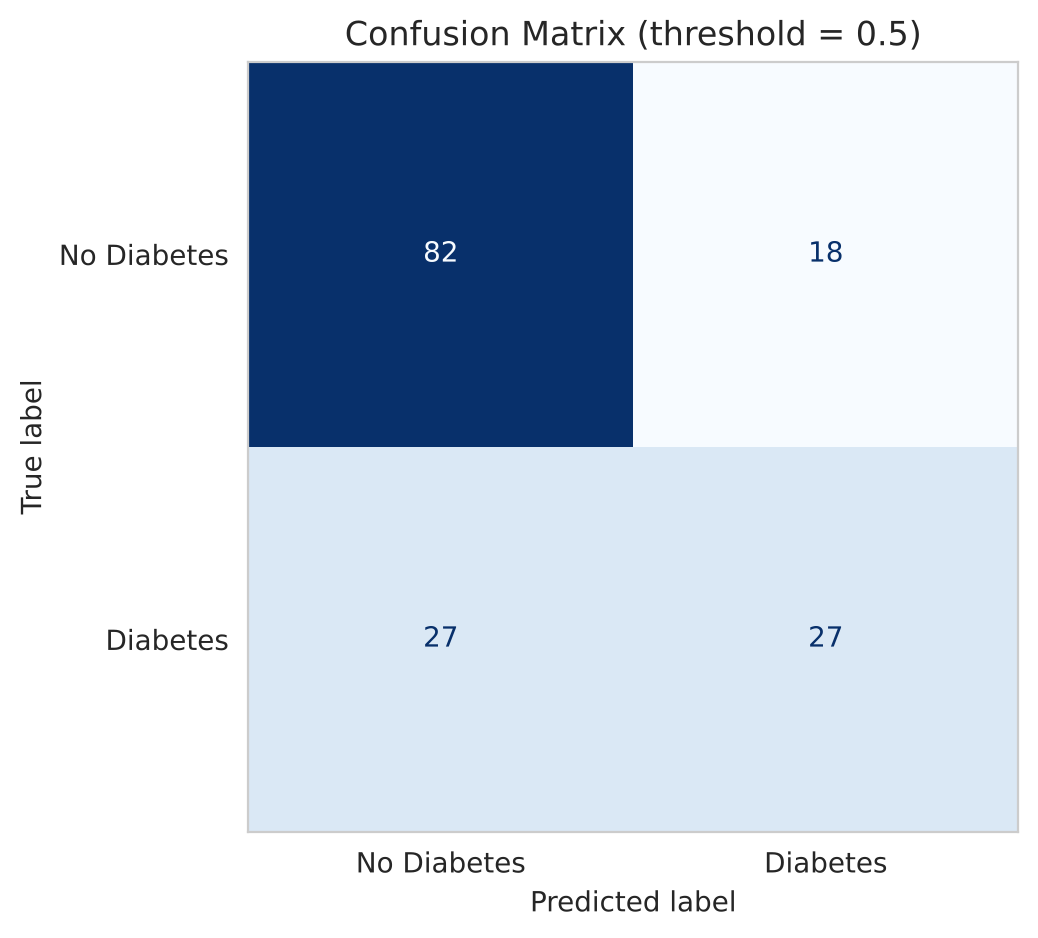

TN = 82  |  FP = 18  |  FN = 27  |  TP = 27

⚠️ 27 diabetes ke mareez model se chhoot gaye (False Negative)


In [18]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (threshold = 0.5)")
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}  |  FP = {fp}  |  FN = {fn}  |  TP = {tp}")
print(f"\n⚠️ {fn} diabetes ke mareez model se chhoot gaye (False Negative)")

### Precision, Recall aur F1 Score 🎯

| Metric | Sawal | Formula | Kab zaroori |
|---|---|---|---|
| **Precision** | Jinko model ne "Diabetes" kaha, unme se kitne **sach mein** mareez thay? | TP / (TP + FP) | Jab jhoota alarm mehenga ho (jaise spam filter, asal email spam mein na jaye) |
| **Recall** | Jitne asal mareez thay, unme se model ne **kitne pakray**? | TP / (TP + FN) | Jab koi mareez chhootna nahi chahiye (**medical!** 🩺) |
| **F1 Score** | Precision aur Recall ka balance | Dono ka harmonic mean | Jab dono zaroori hon |

**Medical misaal:** Agar model sehatmand insaan ko mareez keh de (FP), to wo bas ek extra test karwa le ga. Lekin agar mareez ko sehatmand keh de (FN), to uska ilaaj nahi hoga! Isliay yahan **Recall bohat zaroori** hai.

In [19]:
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



**Samjho:** `Diabetes` wali row mein **Recall** dekho. Model asal mareezon mein se sirf **aadhe** pakar raha hai! Accuracy theek thi, lekin medical ke liay ye kaafi nahi. 😟

Kya isay behtar kar sakte hain? **Haan, threshold badal kar!**

---
## Step 10: Threshold badalna 🎚️

Default threshold **0.5** hai. Agar hum isay **kam** kar dein (jaise 0.3), to model thore se shak pe bhi "Diabetes" keh dega:
- ✅ Zyada mareez pakray jayein ge (**Recall barhe ga**)
- ❌ Kuch sehatmand log bhi pakray jayein ge (**Precision thori gire gi**)

Ye ek **trade-off** hai. Chalo alag thresholds try karte hain:

In [20]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (y_prob >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Accuracy": round(accuracy_score(y_test, pred_t), 3),
        "Precision": round(precision_score(y_test, pred_t), 3),
        "Recall": round(recall_score(y_test, pred_t), 3),
        "F1": round(f1_score(y_test, pred_t), 3),
        "Chhoote mareez (FN)": int(((pred_t == 0) & (y_test == 1)).sum())
    })

pd.DataFrame(rows)

,Threshold,Accuracy,Precision,Recall,F1,Chhoote mareez (FN)
0,0.3,0.740,0.597,0.796,0.683,11
1,0.4,0.734,0.614,0.648,0.631,19
2,0.5,0.708,0.600,0.500,0.545,27
3,0.6,0.721,0.641,0.463,0.538,29
4,0.7,0.727,0.714,0.370,0.488,34


Dekho! Threshold **0.5 se 0.3** karne pe Recall bohat barh gaya aur chhoote hue mareez kaafi kam ho gaye. Is data pe to Accuracy bhi gir nahi rahi. Medical screening ke liay ye **behtar** setting hai. 👍

> 💡 **Threshold ka faisla business ya maqsad pe hota hai, sirf math pe nahi.** Screening test mein low threshold, aur jahan jhoota alarm mehenga ho wahan high threshold.

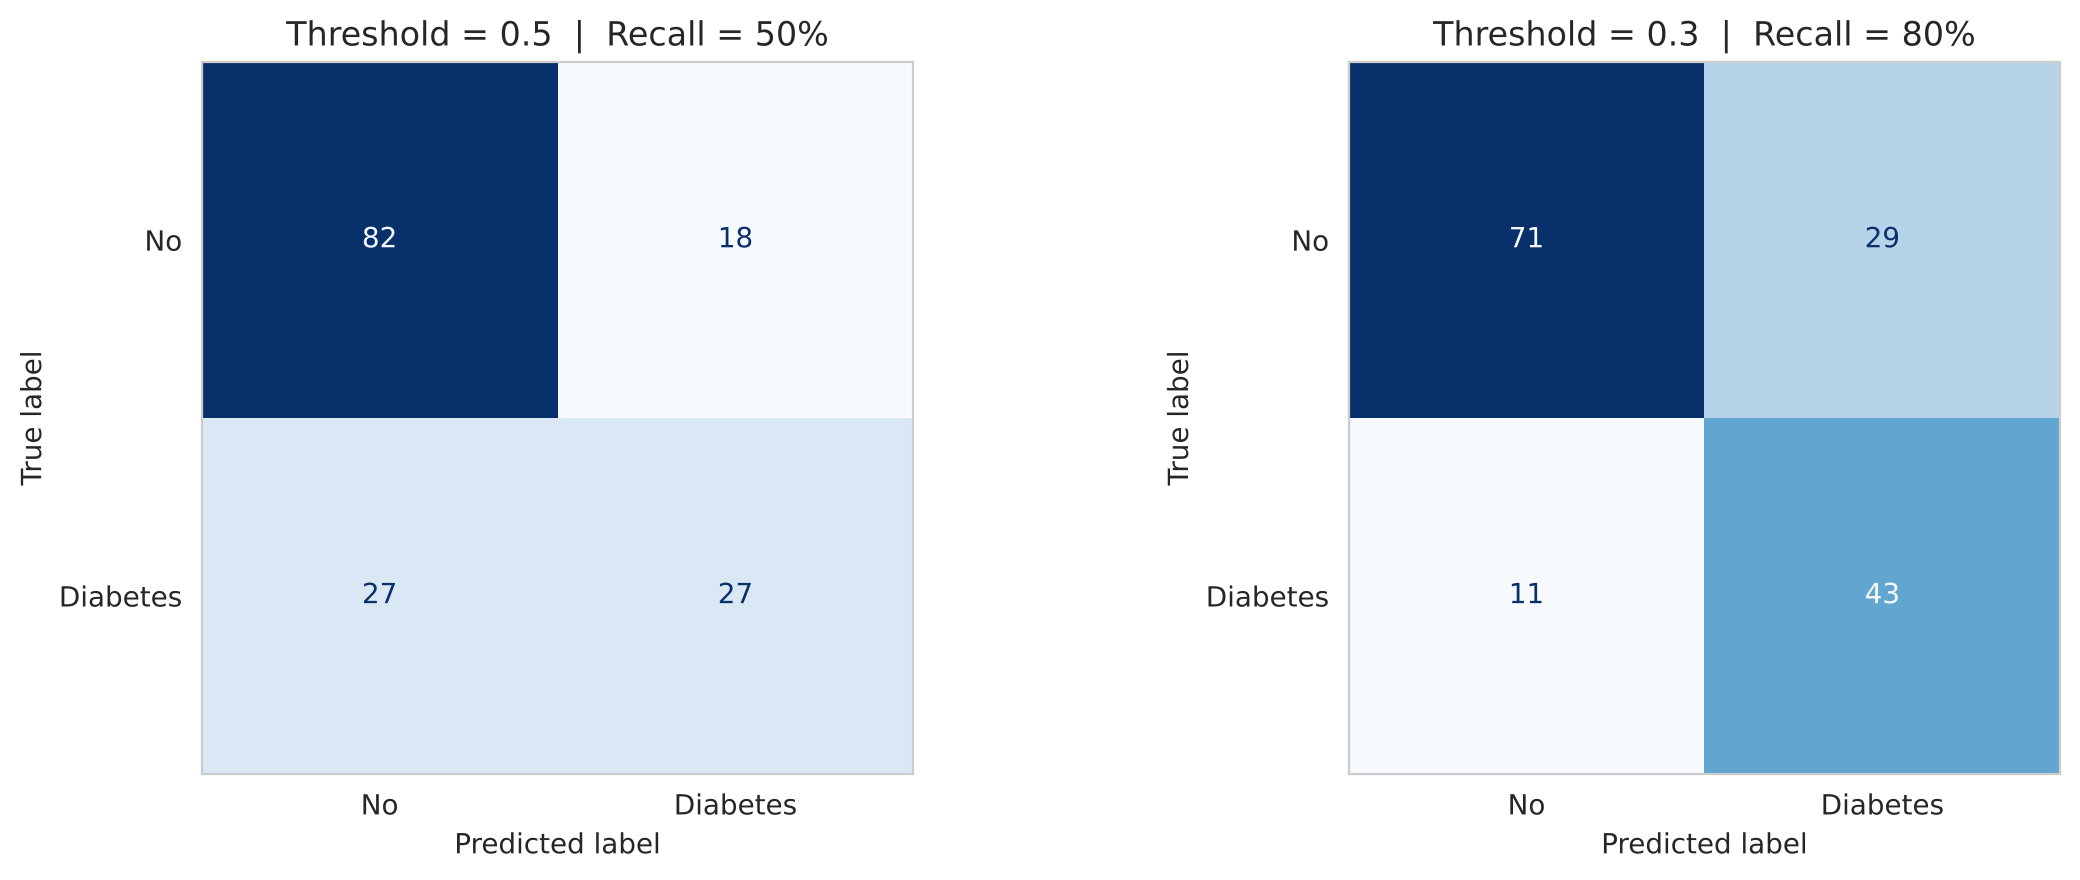

In [21]:
threshold = 0.3
y_pred_03 = (y_prob >= threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, t in [(axes[0], y_pred, 0.5), (axes[1], y_pred_03, threshold)]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["No", "Diabetes"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Threshold = {t}  |  Recall = {recall_score(y_test, pred):.0%}")
    ax.grid(False)
plt.tight_layout()
plt.show()

### Bonus: ROC Curve aur AUC 📈
ROC curve **har mumkin threshold** pe model ka performance ek sath dikhati hai. **AUC** (Area Under Curve) ek number mein batata hai model **mareez aur sehatmand ko kitna acha alag** kar paata hai:
- **1.0** = Perfect 🏆
- **0.5** = Sikka uchhalne jaisa (bekaar) 🪙

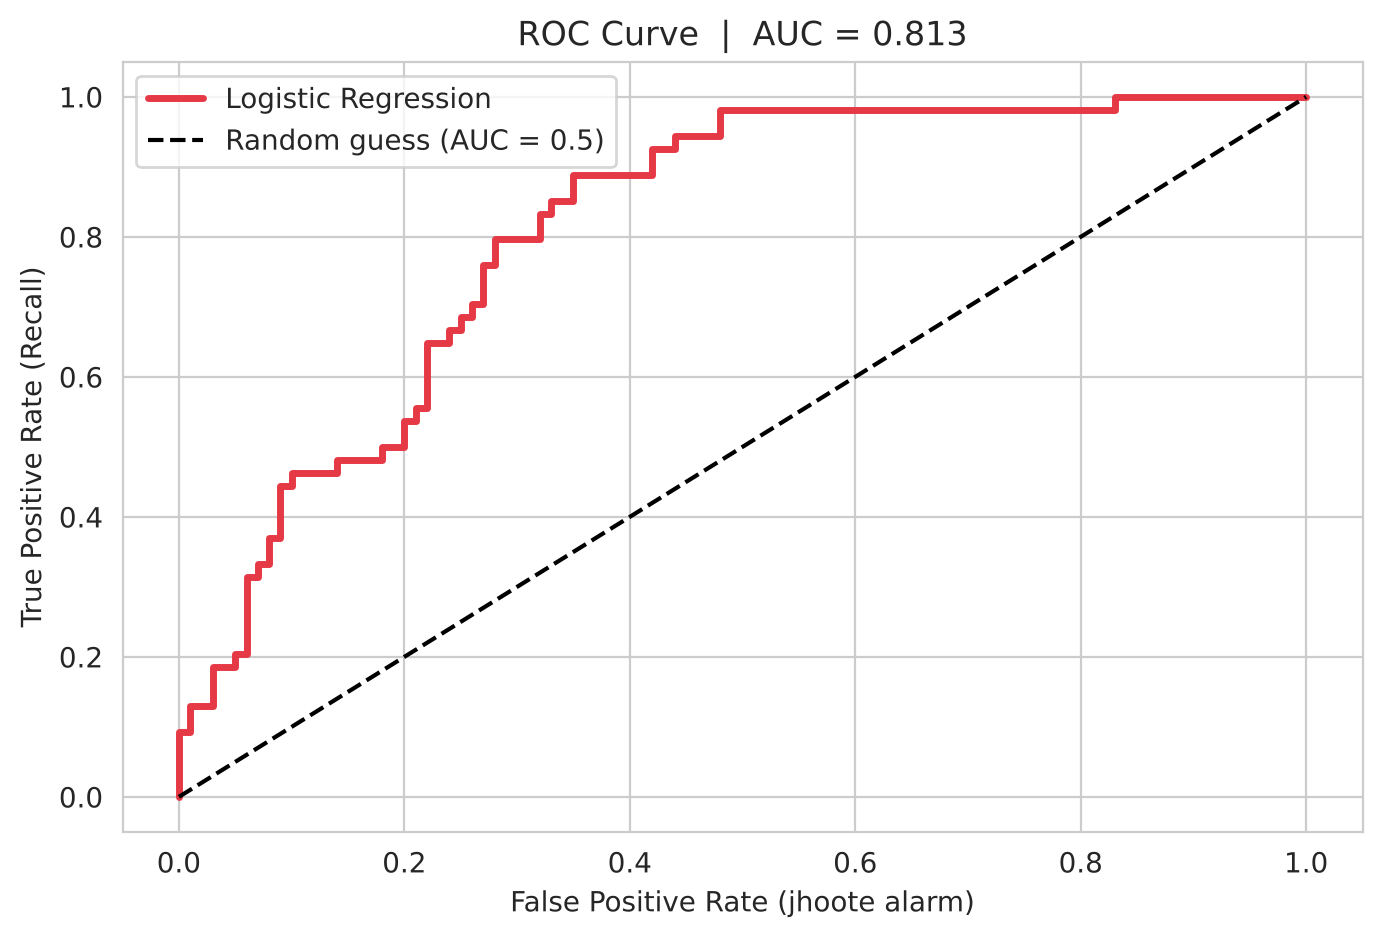

In [22]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, color="#E63946", linewidth=2.5, label="Logistic Regression")
plt.xlabel("False Positive Rate (jhoote alarm)")
plt.ylabel("True Positive Rate (Recall)")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.title(f"ROC Curve  |  AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.legend()
plt.show()

---
## Step 11: Kaunsa feature sab se zyada asar daalta hai? 🔎

Logistic Regression ke coefficients batate hain ke feature barhne se diabetes ka chance **barhta** hai (positive) ya **ghatta** hai (negative). Data scaled hai, isliay yahan features ko aapas mein compare kar sakte hain.

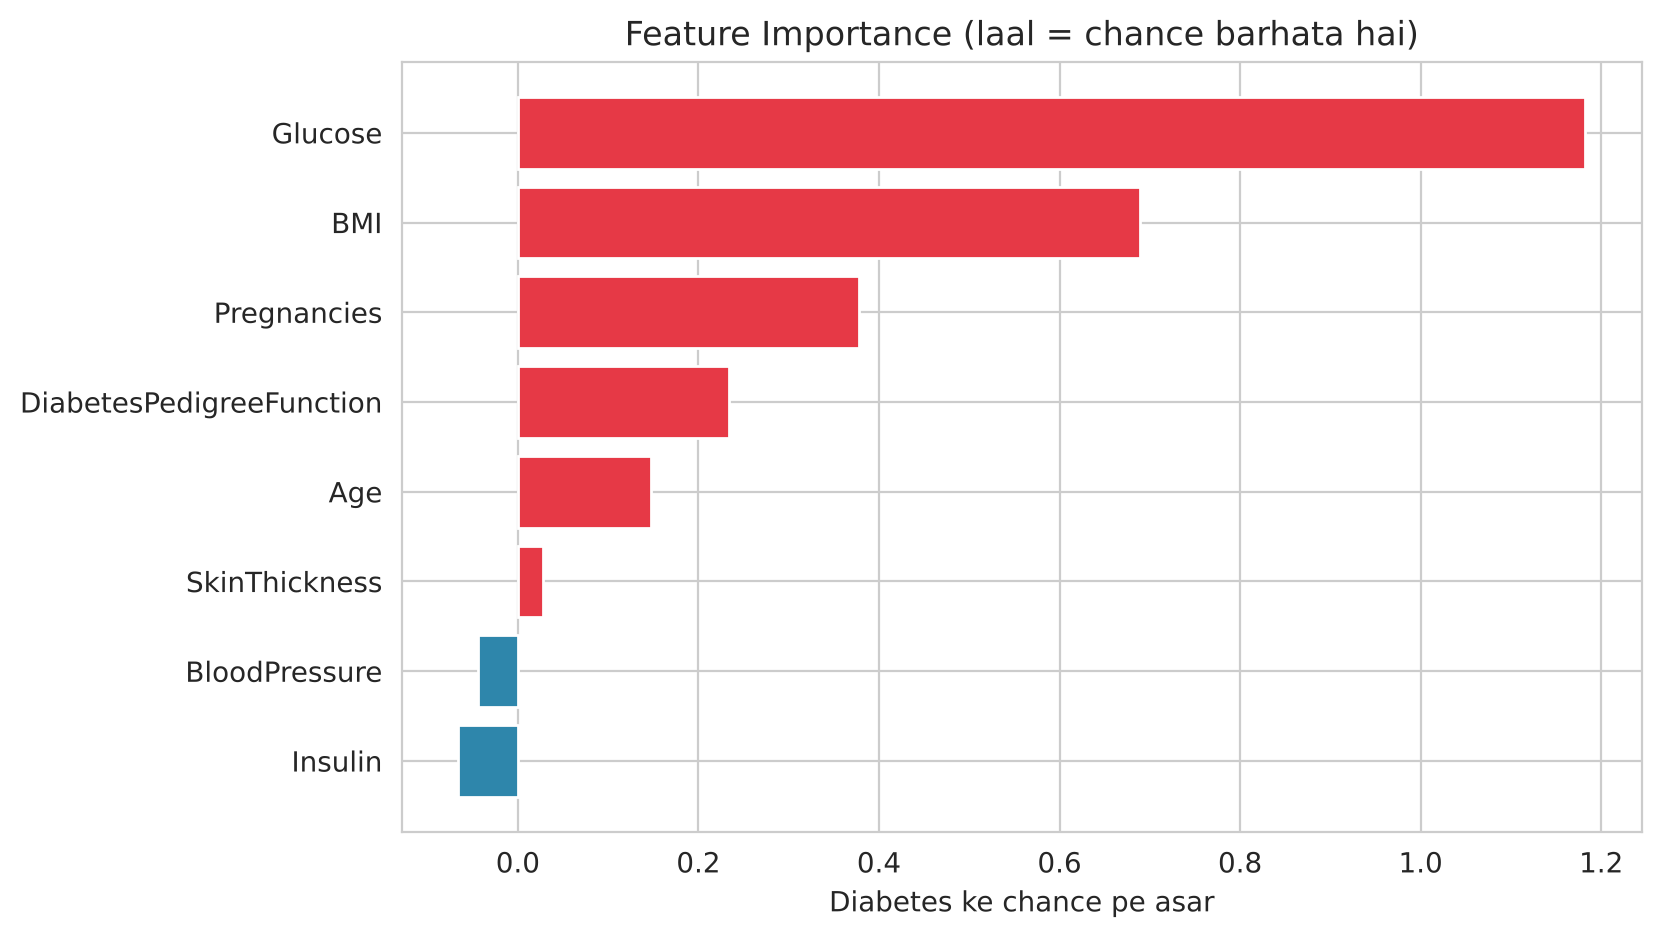

In [23]:
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.named_steps["model"].coef_[0]
}).sort_values("Coefficient")

colors = ["#E63946" if v > 0 else "#2E86AB" for v in coef["Coefficient"]]
plt.barh(coef["Feature"], coef["Coefficient"], color=colors)
plt.xlabel("Diabetes ke chance pe asar")
plt.title("Feature Importance (laal = chance barhata hai)")
plt.show()

Jaisa boxplot mein dekha tha, **Glucose sab se aage** hai. BMI aur Pregnancies bhi chance barhate hain. Model ne ye sab **khud data se seekha**. 🎉

---
# 💾 Step 12: Model ko Pickle file mein save karna

Pichli class ki tarah, model ke sath **threshold** bhi save karein ge, kyunke humne 0.3 chuna hai. Pipeline ke andar imputer aur scaler bhi hain, to naye data ki safai bhi khud ho jaye gi.

In [24]:
model_package = {
    "model": model,
    "threshold": threshold,
    "features": list(X.columns),
    "zero_means_missing": zero_not_possible
}

with open("diabetes_logistic_model.pkl", "wb") as file:
    pickle.dump(model_package, file)

print("Model save ho gaya: diabetes_logistic_model.pkl ✅")

Model save ho gaya: diabetes_logistic_model.pkl ✅


### Load kar ke naye mareez pe test karna 🧪

In [25]:
with open("diabetes_logistic_model.pkl", "rb") as file:
    loaded = pickle.load(file)

def check_diabetes(pregnancies, glucose, blood_pressure, skin_thickness,
                   insulin, bmi, pedigree, age, package=loaded):
    patient = pd.DataFrame([[pregnancies, glucose, blood_pressure, skin_thickness,
                             insulin, bmi, pedigree, age]], columns=package["features"])

    # Wohi preprocessing: 0 ka matlab missing
    patient[package["zero_means_missing"]] = patient[package["zero_means_missing"]].replace(0, np.nan)

    chance = package["model"].predict_proba(patient)[0, 1]
    result = "Diabetes ka khatra ⚠️" if chance >= package["threshold"] else "Khatra kam ✅"
    print(f"Diabetes ka chance: {chance:.0%}  ->  {result}")


check_diabetes(pregnancies=1, glucose=95, blood_pressure=70, skin_thickness=25,
               insulin=80, bmi=23.5, pedigree=0.3, age=25)

check_diabetes(pregnancies=6, glucose=170, blood_pressure=85, skin_thickness=35,
               insulin=0, bmi=36.0, pedigree=0.8, age=50)   # insulin maloom nahi, to 0

Diabetes ka chance: 3%  ->  Khatra kam ✅
Diabetes ka chance: 89%  ->  Diabetes ka khatra ⚠️


> ⚠️ Kabhi bhi anjaan insaan ki di hui `.pkl` file load na karo, usme chhupa code ho sakta hai. 🔒

> 💡 **Colab mein file download karni ho:**
> ```python
> from google.colab import files
> files.download("diabetes_logistic_model.pkl")
> ```

---
## 📚 Summary: Aaj humne kya seekha

1. **Classification:** Number ki jagah category predict karna (Haan/Nahi)
2. **Logistic Regression:** Linear equation + **Sigmoid** = 0 se 1 ke beech probability, phir **threshold** se faisla
3. **Hidden missing values:** 0 wali na-mumkin values ko NaN banaya aur **median** se fill kiya (Pipeline ke andar, taa ke **data leakage** na ho)
4. **Class Imbalance:** `stratify` lagaya aur samjha ke sirf accuracy dhoka de sakti hai
5. **Confusion Matrix, Precision, Recall, F1, ROC/AUC**
6. **Threshold** kam kar ke zyada mareez pakray (Recall barhaya)
7. **C** (regularization) aur **max_iter** (kitne qadam) hyperparameters
8. Model + threshold ko **Pickle** mein save kar ke dobara use kiya

| | Linear / Polynomial Regression | Logistic Regression |
|---|---|---|
| Kaam | Number predict karna | Class predict karna |
| Output | Koi bhi number | 0 se 1 probability ➜ 0 ya 1 |
| Evaluation | MAE, RMSE, R² | Accuracy, Precision, Recall, F1, AUC |

---
## ✍️ Homework / Practice

1. Step 4.1 ko skip kar ke (zeros ko NaN na bana kar) poora notebook chalao. Accuracy aur Recall pe kya farq para?
2. `SimpleImputer(strategy="median")` ko `"mean"` kar ke dekho. Koi farq aaya?
3. `LogisticRegression(..., class_weight="balanced")` add karo. Ye model ko kehta hai ke kam wali class (Diabetes) pe zyada dhyan do. Recall pe kya asar hua?
4. `check_diabetes()` mein sirf **Glucose** ko 90 se 200 tak badal kar dekho chance kaise barhta hai
5. **Socho:** Agar ye model cancer screening ke liay hota, to aap threshold kitna rakhte aur kyun?

**Shabash! Aapne apna pehla Classification model bana liya. 🎓**